In [3]:

%pip install -q --upgrade kaggle

import os
import getpass
import pandas as pd
from pathlib import Path
from kaggle.api.kaggle_api_extended import KaggleApi

# -----------------------------
# 1. Kaggle authentication
# -----------------------------

KAGGLE_USERNAME = os.environ.get("KAGGLE_USERNAME")
KAGGLE_KEY = os.environ.get("KAGGLE_KEY")

if not KAGGLE_USERNAME:
    KAGGLE_USERNAME = input("Kaggle username: ")

if not KAGGLE_KEY:
    KAGGLE_KEY = getpass.getpass("Kaggle API key: ")

# os.environ["KAGGLE_USERNAME"] = "YOUR_KAGGLE_USERNAME"
# os.environ["KAGGLE_KEY"] = "YOUR_KAGGLE_KEY"

KAGGLE_DIR = Path.home() / ".kaggle"
KAGGLE_DIR.mkdir(parents=True, exist_ok=True)

import json

with open(KAGGLE_DIR / "kaggle.json", "w") as f:
    json.dump({
        "username": KAGGLE_USERNAME,
        "key": KAGGLE_KEY
    }, f)

os.chmod(KAGGLE_DIR / "kaggle.json", 0o600)

api = KaggleApi()
api.authenticate()

print("Kaggle authentication successful!")

# -----------------------------
# 2. Download EMNIST
# -----------------------------

DOWNLOAD_PATH = Path.cwd() / "data" / "emnist"
DOWNLOAD_PATH.mkdir(parents=True, exist_ok=True)

api.dataset_download_files(
    "crawford/emnist",
    path=str(DOWNLOAD_PATH),
    unzip=True
)

print("Dataset downloaded:", DOWNLOAD_PATH)

# -----------------------------
# 3. Load dataset
# -----------------------------

train_path = DOWNLOAD_PATH / "emnist-letters-train.csv"
test_path = DOWNLOAD_PATH / "emnist-letters-test.csv"

if not train_path.exists() or not test_path.exists():
    raise FileNotFoundError(
        f"EMNIST CSV files not found in {DOWNLOAD_PATH}"
    )

train = pd.read_csv(train_path, header=None)
test = pd.read_csv(test_path, header=None)

print("\nDataset loaded!")
print("Training:", train.shape)
print("Testing:", test.shape)

display(train.head())


Kaggle authentication successful!
Dataset URL: https://www.kaggle.com/datasets/crawford/emnist
Dataset downloaded: /content/data/emnist

Dataset loaded!
Training: (88800, 785)
Testing: (14800, 785)


,0,1,2,3,4,5,6,7,8,9,...,775,776,777,778,779,780,781,782,783,784
0,23,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,16,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,15,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,23,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


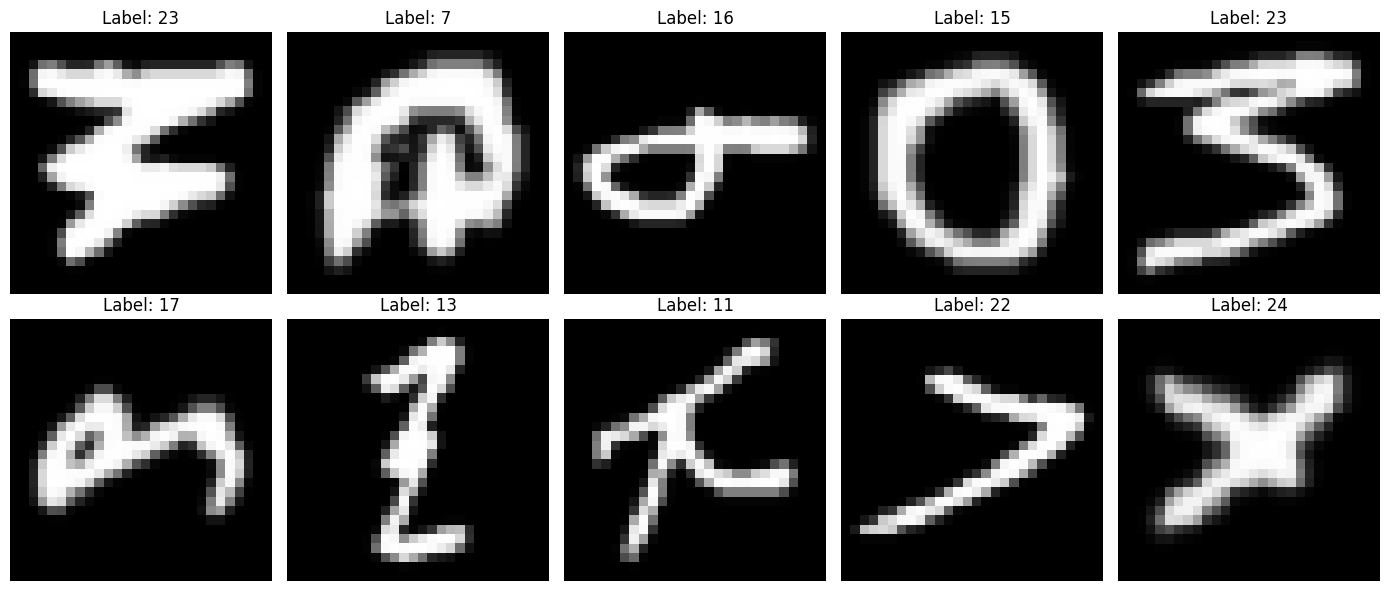

In [5]:
import matplotlib.pyplot as plt
import numpy as np

# Separate labels and pixel values
X = train.iloc[:, 1:].values
y = train.iloc[:, 0].values

fig, axes = plt.subplots(2, 5, figsize=(14, 6))

for i, ax in enumerate(axes.flat):
    image = X[i].reshape(28, 28)

    ax.imshow(image, cmap="gray")
    ax.set_title(f"Label: {y[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [6]:
train[0].value_counts()

,count
0,
25,3453
11,3438
5,3437
24,3437
20,3436
17,3435
16,3430
9,3428
26,3427


In [7]:
images = []

for i in range(len(train)):
    image = train.iloc[i, 1:].values.reshape(28, 28)

    new = np.rot90(image, k=-1)
    new = np.fliplr(new)

    images.append(new.flatten())

images = np.array(images)

In [8]:
train = pd.DataFrame(
    np.column_stack((train.iloc[:, 0].values, images))
)

print(train.shape)

(88800, 785)


In [9]:
images = []

for i in range(len(test)):
    image = test.iloc[i, 1:].values.reshape(28, 28)

    new = np.rot90(image, k=-1)
    new = np.fliplr(new)

    images.append(new.flatten())

images = np.array(images)

test = pd.DataFrame(
    np.column_stack((test.iloc[:, 0].values, images))
)

print(test.shape)

(14800, 785)


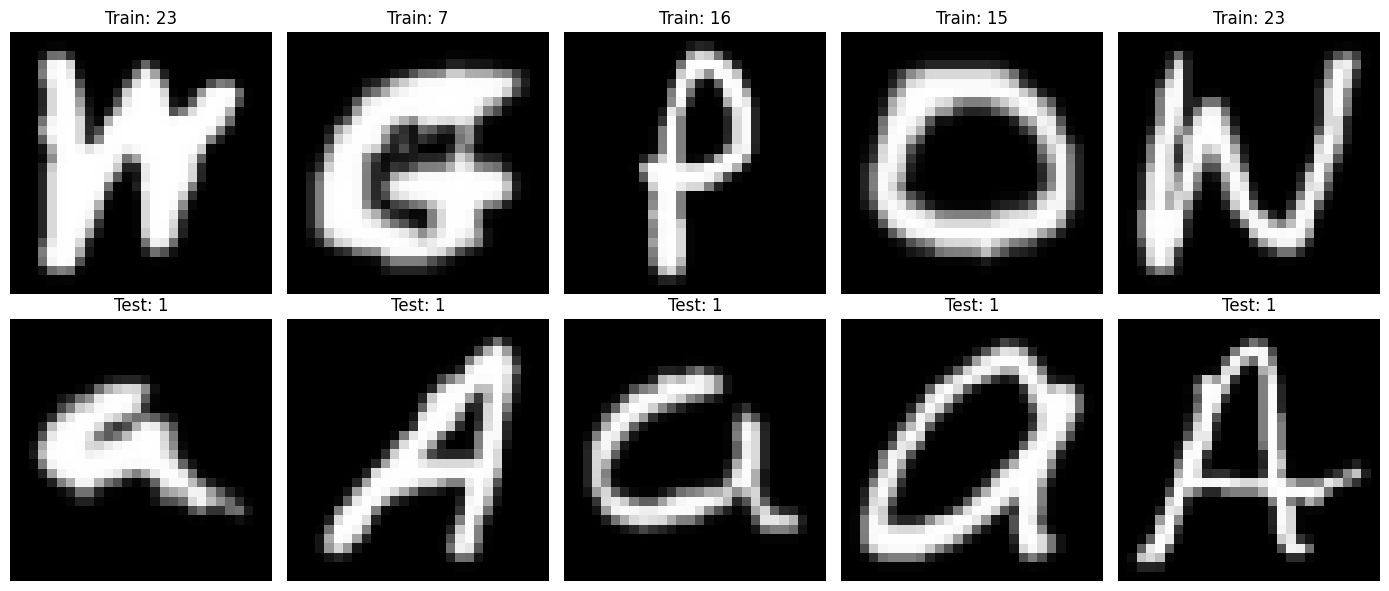

In [10]:
fig, axes = plt.subplots(2, 5, figsize=(14, 6))

for i in range(5):
    # Training samples
    train_img = train.iloc[i, 1:].values.reshape(28, 28)
    axes[0, i].imshow(train_img, cmap='gray')
    axes[0, i].set_title(f"Train: {train.iloc[i, 0]}")
    axes[0, i].axis('off')

    # Testing samples
    test_img = test.iloc[i, 1:].values.reshape(28, 28)
    axes[1, i].imshow(test_img, cmap='gray')
    axes[1, i].set_title(f"Test: {test.iloc[i, 0]}")
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

In [11]:
xtrain = train.iloc[:, 1:].values
ytrain = train.iloc[:, 0].values

xtest = test.iloc[:, 1:].values
ytest = test.iloc[:, 0].values

xtrain = xtrain.astype("float32") / 255.0
xtest = xtest.astype("float32") / 255.0

ytrain = ytrain - 1
ytest = ytest - 1

In [12]:
xtrain = xtrain.reshape(-1, 28, 28, 1)
xtest = xtest.reshape(-1, 28, 28, 1)

In [20]:
from sklearn.model_selection import train_test_split

X_train_new, X_val, y_train_new, y_val = train_test_split(
    xtrain,
    ytrain,
    test_size=0.2,
    random_state=42,
    stratify=ytrain
)

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout


model1 = Sequential([
    Conv2D(32, kernel_size=(3,3), activation="relu", input_shape=(28, 28, 1)),
    MaxPooling2D(pool_size=(2,2)),
    Conv2D(32, kernel_size=(3,3), activation="relu"),
    MaxPooling2D(pool_size=(2,2)),
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(26, activation="softmax")
])


model1.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model1.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 26, 26, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 13, 13, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 11, 11, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 256)            │       205,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 26)             │         6,682 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 230,842 (901.73 KB)

 Trainable params: 230,842 (901.73 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history1 = model1.fit(
    X_train_new,
    y_train_new,
    epochs=5,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/5
1110/1110 ━━━━━━━━━━━━━━━━━━━━ 38s 33ms/step - accuracy: 0.6892 - loss: 1.0137 - val_accuracy: 0.8780 - val_loss: 0.3987
Epoch 2/5
1110/1110 ━━━━━━━━━━━━━━━━━━━━ 39s 32ms/step - accuracy: 0.8347 - loss: 0.5235 - val_accuracy: 0.8975 - val_loss: 0.3129
Epoch 3/5
1110/1110 ━━━━━━━━━━━━━━━━━━━━ 34s 31ms/step - accuracy: 0.8595 - loss: 0.4337 - val_accuracy: 0.9105 - val_loss: 0.2731
Epoch 4/5
1110/1110 ━━━━━━━━━━━━━━━━━━━━ 35s 31ms/step - accuracy: 0.8762 - loss: 0.3841 - val_accuracy: 0.9199 - val_loss: 0.2490
Epoch 5/5
1110/1110 ━━━━━━━━━━━━━━━━━━━━ 41s 31ms/step - accuracy: 0.8865 - loss: 0.3500 - val_accuracy: 0.9217 - val_loss: 0.2391


In [33]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout


model2 = Sequential([
    Conv2D(32, kernel_size=(3,3), activation="relu", input_shape=(28, 28, 1)),
    MaxPooling2D(pool_size=(2,2)),
    Conv2D(32, kernel_size=(3,3), activation="relu"),
    MaxPooling2D(pool_size=(2,2)),
    Flatten(),
    Dense(256, activation="relu"),
    Dropout(0.6),
    Dense(26, activation="softmax")
])


model2.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model2.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_14 (Conv2D)              │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 11, 11, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_7 (Flatten)             │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 256)            │       205,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 26)             │         6,682 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 221,306 (864.48 KB)

 Trainable params: 221,306 (864.48 KB)

 Non-trainable params: 0 (0.00 B)

In [34]:
history2 = model2.fit(
    X_train_new,
    y_train_new,
    epochs=20,
    batch_size=128,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/20


555/555 ━━━━━━━━━━━━━━━━━━━━ 36s 63ms/step - accuracy: 0.6950 - loss: 1.0031 - val_accuracy: 0.8812 - val_loss: 0.3808
Epoch 2/20
555/555 ━━━━━━━━━━━━━━━━━━━━ 39s 59ms/step - accuracy: 0.8434 - loss: 0.4931 - val_accuracy: 0.9048 - val_loss: 0.2951
Epoch 3/20
555/555 ━━━━━━━━━━━━━━━━━━━━ 43s 63ms/step - accuracy: 0.8693 - loss: 0.4089 - val_accuracy: 0.9136 - val_loss: 0.2648
Epoch 4/20
555/555 ━━━━━━━━━━━━━━━━━━━━ 34s 62ms/step - accuracy: 0.8841 - loss: 0.3585 - val_accuracy: 0.9216 - val_loss: 0.2416
Epoch 5/20
555/555 ━━━━━━━━━━━━━━━━━━━━ 33s 60ms/step - accuracy: 0.8935 - loss: 0.3291 - val_accuracy: 0.9251 - val_loss: 0.2286
Epoch 6/20
555/555 ━━━━━━━━━━━━━━━━━━━━ 42s 62ms/step - accuracy: 0.9003 - loss: 0.3064 - val_accuracy: 0.9256 - val_loss: 0.2274
Epoch 7/20
555/555 ━━━━━━━━━━━━━━━━━━━━ 41s 63ms/step - accuracy: 0.9068 - loss: 0.2877 - val_accuracy: 0.9304 - val_loss: 0.2143
Epoch 8/20
555/555 ━━━━━━━━━━━━━━━━━━━━ 34s 61ms/step - accuracy: 0.9106 - loss: 0.2697 - val_accurac

In [40]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [41]:
model2.save('/content/drive/MyDrive/emnist_cnn_model2.keras')